# Employee Salary Data Cleaning & Visualization

## 1. Project Overview

This project focuses on cleaning, processing, analyzing, and visualizing an Employee Salary Dataset using Python.

The main objective is to identify data quality issues, handle missing values, detect outliers, remove duplicate records, and create meaningful visualizations to understand employee information.

### Tools and Technologies
- Python
- Google Colab
- Pandas
- NumPy
- Matplotlib
- Seaborn

### Key Objectives
- Handle missing values.
- Identify and treat outliers.
- Detect and remove duplicate records.
- Perform data analysis.
- Create meaningful visualizations.
- Present key findings and insights.

In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


## 2. Loading the Dataset

The Employee Salary Dataset is loaded using the Pandas library. It contains employee details such as name, age, salary, joining date, and department.

The dataset will be used for data cleaning, analysis, and visualization.

In [32]:
df = pd.read_csv('employee_salary_dataset.csv')



In [33]:
df.head()

,Name,Age,Salary,Join_Date,Department,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,...,Unnamed: 16,Unnamed: 17,Unnamed: 18,Unnamed: 19,Unnamed: 20,Unnamed: 21,Unnamed: 22,Unnamed: 23,Unnamed: 24,Unnamed: 25
0,Pam,25.0,70200.0,1/15/2023,HR,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Jane,NaN,65000.0,8/1/2022,Finance,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Alice,22.0,71350.0,5/20/2021,HR,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Bob,22.0,NaN,1/15/2023,IT,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Pam,25.0,71250.0,1/15/2023,HR,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [34]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Number of Rows: 999
Number of Columns: 26


## 3. Initial Data Inspection

Initial data inspection helps us understand the structure, size, quality, and contents of the dataset before performing data cleaning.

In this section, we will examine the dataset dimensions, column names, data types, missing values, and duplicate records.

In [35]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape: (999, 26)

Column Names:
['Name', 'Age', 'Salary', 'Join_Date', 'Department', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7', 'Unnamed: 8', 'Unnamed: 9', 'Unnamed: 10', 'Unnamed: 11', 'Unnamed: 12', 'Unnamed: 13', 'Unnamed: 14', 'Unnamed: 15', 'Unnamed: 16', 'Unnamed: 17', 'Unnamed: 18', 'Unnamed: 19', 'Unnamed: 20', 'Unnamed: 21', 'Unnamed: 22', 'Unnamed: 23', 'Unnamed: 24', 'Unnamed: 25']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 999 entries, 0 to 998
Data columns (total 26 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Name         43 non-null     object 
 1   Age          39 non-null     float64
 2   Salary       36 non-null     float64
 3   Join_Date    43 non-null     object 
 4   Department   43 non-null     object 
 5   Unnamed: 5   0 non-null      float64
 6   Unnamed: 6   0 non-null      float64
 7   Unnamed: 7   0 non-null      float64
 8   Unnamed: 8   0 non-null      float64
 9   Unn

In [36]:
print("Missing Values in Each Column:")
print(df.isnull().sum())

Missing Values in Each Column:
Name           956
Age            960
Salary         963
Join_Date      956
Department     956
Unnamed: 5     999
Unnamed: 6     999
Unnamed: 7     999
Unnamed: 8     999
Unnamed: 9     999
Unnamed: 10    999
Unnamed: 11    999
Unnamed: 12    999
Unnamed: 13    999
Unnamed: 14    999
Unnamed: 15    999
Unnamed: 16    999
Unnamed: 17    999
Unnamed: 18    999
Unnamed: 19    999
Unnamed: 20    999
Unnamed: 21    999
Unnamed: 22    999
Unnamed: 23    999
Unnamed: 24    999
Unnamed: 25    999
dtype: int64


In [37]:
print("Number of Duplicate Rows:", df.duplicated().sum())

Number of Duplicate Rows: 956


## 4. Data Cleaning

Data cleaning is the process of identifying and correcting errors, removing unnecessary data, and improving data quality.

In this section, we will remove completely empty rows and columns before handling missing values, duplicates, and outliers.

In [38]:
# Remove completely empty columns
df.dropna(axis=1, how='all', inplace=True)

# Remove completely empty rows
df.dropna(axis=0, how='all', inplace=True)

print("Shape after removing empty rows and columns:", df.shape)

display(df.head())

Shape after removing empty rows and columns: (43, 5)


,Name,Age,Salary,Join_Date,Department
0,Pam,25.0,70200.0,1/15/2023,HR
1,Jane,NaN,65000.0,8/1/2022,Finance
2,Alice,22.0,71350.0,5/20/2021,HR
3,Bob,22.0,NaN,1/15/2023,IT
4,Pam,25.0,71250.0,1/15/2023,HR


In [39]:
print("Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

Dataset Shape: (43, 5)

Missing Values:
Name          0
Age           4
Salary        7
Join_Date     0
Department    0
dtype: int64

Duplicate Records:
1


### 4.2 Handling Duplicate Records

Duplicate records are repeated entries in a dataset. They can affect the accuracy of data analysis.

We will identify exact duplicate rows and remove unnecessary repetitions while keeping one original record.

In [40]:
duplicate_rows = df[df.duplicated(keep=False)]

display(duplicate_rows)

,Name,Age,Salary,Join_Date,Department
8,Sam,40.0,NaN,9/5/2022,IT
31,Sam,40.0,NaN,9/5/2022,IT


In [41]:
df.drop_duplicates(inplace=True)

print("Shape after removing duplicates:", df.shape)
print("Remaining duplicates:", df.duplicated().sum())

Shape after removing duplicates: (42, 5)
Remaining duplicates: 0


### 4.3 Handling Missing Values

Missing values occur when certain information is not available in a dataset.

In our Employee Salary Dataset, the Age and Salary columns contain missing values.

We will use the median to fill these missing numerical values because it is less affected by extreme values compared to the mean.

In [42]:
print("Median Age:", df['Age'].median())
print("Median Salary:", df['Salary'].median())

Median Age: 36.0
Median Salary: 71841.0


In [43]:
df['Age'] = df['Age'].fillna(df['Age'].median())

df['Salary'] = df['Salary'].fillna(df['Salary'].median())

print("Missing values after treatment:")
print(df.isnull().sum())

Missing values after treatment:
Name          0
Age           0
Salary        0
Join_Date     0
Department    0
dtype: int64


### 4.4 Outlier Detection

Outliers are data values that are significantly different from other observations.

In this project, we will use the Interquartile Range (IQR) method to identify unusually high or low employee salaries.

Outliers will be investigated before deciding whether any treatment is necessary.

In [44]:
Q1 = df['Salary'].quantile(0.25)
Q3 = df['Salary'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)

Q1: 68500.0
Q3: 77421.0
IQR: 8921.0
Lower Limit: 55118.5
Upper Limit: 90802.5


In [45]:
outliers = df[
    (df['Salary'] < lower_limit) |
    (df['Salary'] > upper_limit)
]

print("Number of Potential Outliers:", len(outliers))

display(outliers[['Name', 'Salary', 'Department']])

Number of Potential Outliers: 6


,Name,Salary,Department
6,Joanne,120000.0,IT
15,Susy,126001.0,IT
18,Joanne,125600.0,IT
21,Norma,921000.0,IT
28,Jenny,801423.0,IT
42,Kim,546222.0,HR


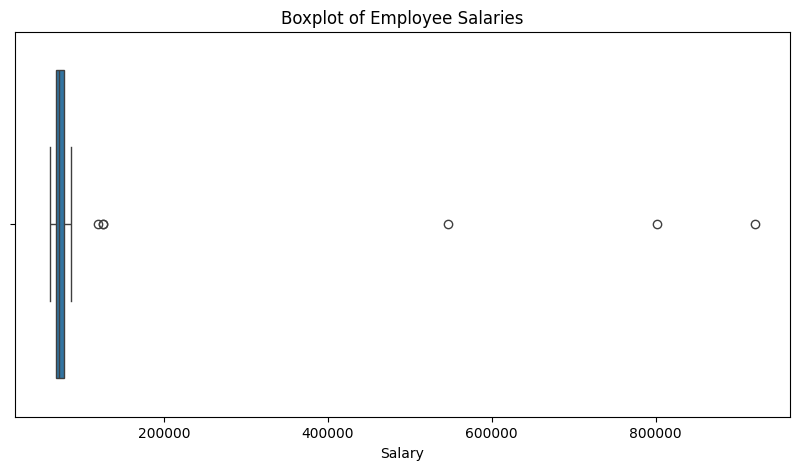

In [46]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=df['Salary'])

plt.title("Boxplot of Employee Salaries")
plt.xlabel("Salary")

plt.show()

In [47]:
print("Potential Outlier Records:")

display(
    outliers[['Name', 'Age', 'Salary', 'Department']]
    .sort_values(by='Salary', ascending=False)
)

Potential Outlier Records:


,Name,Age,Salary,Department
21,Norma,51.0,921000.0,IT
28,Jenny,36.0,801423.0,IT
42,Kim,33.0,546222.0,HR
15,Susy,41.0,126001.0,IT
18,Joanne,25.0,125600.0,IT
6,Joanne,25.0,120000.0,IT


In [48]:
print("Total Employees:", len(df))
print("Potential Outliers:", len(outliers))
print("Percentage of Outliers:", round(len(outliers) / len(df) * 100, 2), "%")

Total Employees: 42
Potential Outliers: 6
Percentage of Outliers: 14.29 %


### 4.5 Outlier Treatment

Outliers were identified using the Interquartile Range (IQR) method.

To reduce the influence of extreme salary values, IQR capping is applied. The original salary values are preserved for reference, while the capped values are used for further analysis and visualization.

In [49]:
# Preserve original salary values
df['Original_Salary'] = df['Salary']

# Apply IQR capping
df['Salary'] = df['Salary'].clip(
    lower=lower_limit,
    upper=upper_limit
)

print("Outlier Treatment Completed!")

print("\nOriginal and Capped Salaries:")
display(df[['Name', 'Original_Salary', 'Salary']].sort_values(
    by='Original_Salary', ascending=False
).head(10))

Outlier Treatment Completed!

Original and Capped Salaries:


,Name,Original_Salary,Salary
21,Norma,921000.0,90802.5
28,Jenny,801423.0,90802.5
42,Kim,546222.0,90802.5
15,Susy,126001.0,90802.5
18,Joanne,125600.0,90802.5
6,Joanne,120000.0,90802.5
41,Pam,86548.0,86548.0
9,Eli,80100.0,80100.0
14,Pamela,77421.0,77421.0
23,Eli,77421.0,77421.0


In [50]:
remaining_outliers = df[
    (df['Salary'] < lower_limit) |
    (df['Salary'] > upper_limit)
]

print("Remaining Outliers:", len(remaining_outliers))

Remaining Outliers: 0


### 4.6 Data Type Correction

Data types define how values are stored in a dataset.

In this section, we will convert the Age and Salary columns into integer format and the Join_Date column into datetime format to ensure accurate analysis.

In [51]:
print(df.dtypes)

Name                object
Age                float64
Salary             float64
Join_Date           object
Department          object
Original_Salary    float64
dtype: object


In [52]:
df['Age'] = df['Age'].astype(int)

df['Salary'] = df['Salary'].round(0).astype(int)

df['Join_Date'] = pd.to_datetime(
    df['Join_Date'],
    errors='coerce'
)

print("Data types after conversion:")
print(df.dtypes)

Data types after conversion:
Name                       object
Age                         int64
Salary                      int64
Join_Date          datetime64[ns]
Department                 object
Original_Salary           float64
dtype: object


In [53]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 42 entries, 0 to 42
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   Name             42 non-null     object        
 1   Age              42 non-null     int64         
 2   Salary           42 non-null     int64         
 3   Join_Date        42 non-null     datetime64[ns]
 4   Department       42 non-null     object        
 5   Original_Salary  42 non-null     float64       
dtypes: datetime64[ns](1), float64(1), int64(2), object(2)
memory usage: 2.3+ KB


## 8. Data Visualization

### 8.1 Employee Count by Department

This chart shows the number of employees in each department.

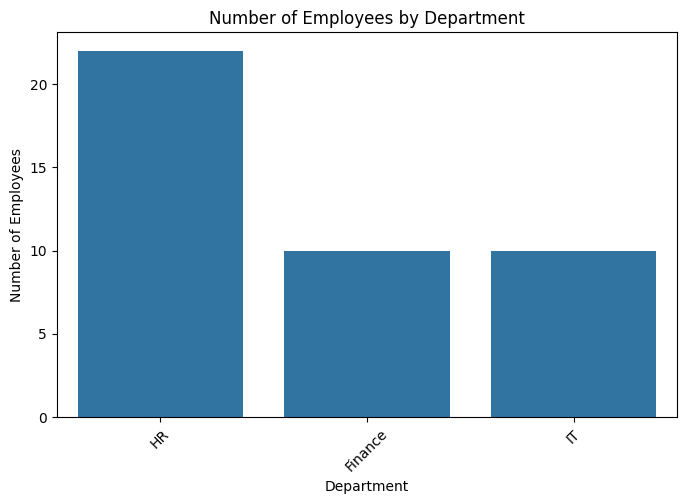

In [54]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='Department')

plt.title('Number of Employees by Department')
plt.xlabel('Department')
plt.ylabel('Number of Employees')
plt.xticks(rotation=45)
plt.show()

### 8.2 Salary Distribution

This histogram shows how employee salaries are distributed in the dataset.

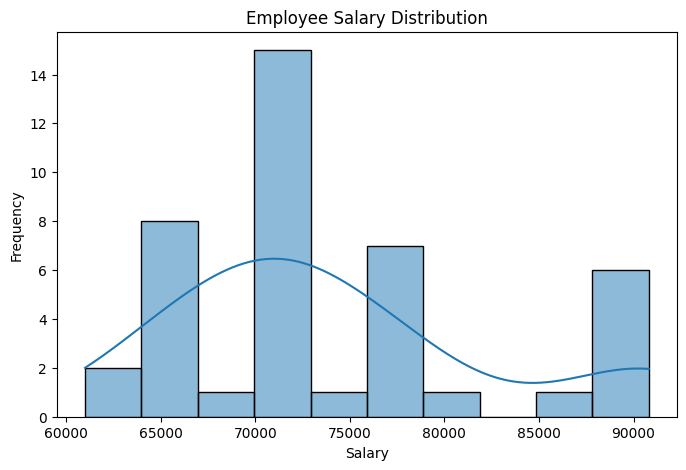

In [55]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x='Salary', bins=10, kde=True)

plt.title('Employee Salary Distribution')
plt.xlabel('Salary')
plt.ylabel('Frequency')
plt.show()

### 8.3 Relationship Between Age and Salary

This scatter plot shows the relationship between employee age and salary.

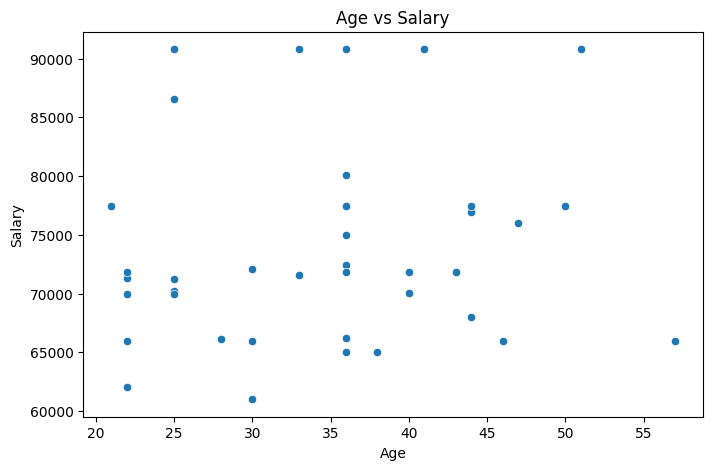

In [56]:
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x='Age', y='Salary')

plt.title('Age vs Salary')
plt.xlabel('Age')
plt.ylabel('Salary')
plt.show()

In [57]:
print("Employee Count by Department:")
print(df['Department'].value_counts())

print("\nSalary Summary:")
print(df['Salary'].describe())

print("\nAverage Age:")
print(round(df['Age'].mean(), 2))

Employee Count by Department:
Department
HR         22
Finance    10
IT         10
Name: count, dtype: int64

Salary Summary:
count       42.000000
mean     74140.023810
std       8506.513027
min      61000.000000
25%      68500.000000
50%      71841.000000
75%      77421.000000
max      90802.000000
Name: Salary, dtype: float64

Average Age:
34.69


## 9. Key Findings

Based on the data cleaning and visualization process, the following findings were observed:

1. **Department Distribution:** HR has the highest number of employees with 22 employees, while Finance and IT have 10 employees each.

2. **Salary Distribution:** The average employee salary is ₹74,140, and the median salary is ₹71,841.

3. **Salary Range:** After outlier treatment, salaries range from ₹61,000 to ₹90,802.

4. **Employee Age:** The average age of employees is approximately 34.69 years.

5. **Data Quality:** Missing values and duplicate records were handled, and the dataset was cleaned for visualization.

## 10. Conclusion

In this project, the raw employee salary dataset was cleaned and processed using Python libraries such as Pandas, Matplotlib, and Seaborn.

Missing values, duplicate records, and outliers were handled. Three visualizations were created to understand department distribution, salary distribution, and the relationship between age and salary.

This project provided practical experience in data preprocessing, visualization, and understanding insights from data.

In [58]:
df.reset_index(drop=True, inplace=True)

df.to_csv('cleaned_employee_salary_dataset.csv', index=False)

from google.colab import files
files.download('cleaned_employee_salary_dataset.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>